# Árboles de Decisión — Regresión (Cell2Cell)

**Objetivo:** predecir el **ingreso mensual del cliente** (`MonthlyRevenue`) con un `DecisionTreeRegressor`, ajustar los hiperparámetros por validación cruzada y comparar contra la regresión lineal del notebook anterior.

**Por qué un árbol y no otra regresión:** la regresión lineal impone una relación recta entre cada variable y el ingreso. Un árbol **no impone forma**: parte el espacio de clientes en regiones y predice el promedio de cada región. Si el efecto de la antigüedad del equipo no es lineal —y en el EDA vimos que no lo es—, el árbol puede capturarlo sin que se lo indiquemos.


## Marco teórico

### Concepto básico

Un árbol de decisión de regresión **divide el espacio de datos en regiones homogéneas** y asigna a cada hoja el **valor promedio** de los clientes que caen ahí.

- **Construcción:** algoritmo **CART** (*Classification and Regression Trees*). En cada nodo busca el corte (variable + umbral) que minimiza el error cuadrático dentro de los dos grupos resultantes.
- **Criterio de corte:** `squared_error` (varianza). El árbol elige el corte que deja los grupos más "puros".
- **Profundidad:** controla la complejidad. Un árbol muy profundo memoriza el entrenamiento (**sobreajuste**); uno muy superficial no captura nada (**subajuste**).

### Cómo se interpreta

Se lee de arriba hacia abajo: cada nodo interno es una pregunta (`CurrentEquipmentDays <= 365.5`), cada rama es la respuesta y cada hoja es el **ingreso promedio predicho** para ese grupo de clientes. Es uno de los modelos más explicables que existen: se puede dibujar y explicar en una reunión.

### Medidas de ajuste

| Métrica | Qué mide | Mejor cuando |
|---|---|---|
| MSE | Error cuadrático medio (USD²) | Bajo |
| RMSE | Raíz del MSE (USD) | Bajo |
| MAE | Error absoluto medio (USD) | Bajo |
| $R^2$ | Varianza explicada | Cerca de 1 |

### Ventajas y desventajas

✅ Captura no linealidades e interacciones sin declararlas. No requiere escalado. Muy interpretable. Robusto a outliers en las $X$.

⚠️ Se sobreajusta con facilidad. Es inestable (un cambio pequeño en los datos puede cambiar el árbol). Predice **escalones**, no una recta: no extrapola fuera del rango observado. Sesgado hacia variables con muchos valores distintos.


## 1. LIBRERÍAS Y FUNCIONES

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import statsmodels.api as sm

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)
sns.set_theme(style='whitegrid')

import sklearn
print('scikit-learn', sklearn.__version__)

scikit-learn 1.9.0


## 2. PARÁMETROS

In [2]:
RUTA_DATOS = 'cell2celltrain.csv'
TARGET     = 'MonthlyRevenue'
TEST_SIZE  = 0.30
SEMILLA    = 22

print(f'Target: {TARGET} | split: {100 - TEST_SIZE * 100:.0f}/{TEST_SIZE * 100:.0f} | semilla: {SEMILLA}')

Target: MonthlyRevenue | split: 70/30 | semilla: 22


## 3. DATOS

In [3]:
df = pd.read_csv(RUTA_DATOS, sep=',', encoding='iso-8859-1', low_memory=False)

print(f'Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}')
print(df[TARGET].describe().round(2).to_string())

Filas: 51,047 | Columnas: 58
count    50891.00
mean        58.83
std         44.51
min         -6.17
25%         33.61
50%         48.46
75%         71.06
max       1223.38


### 3.1 Preparación

Se reutiliza la misma matriz de diseño del notebook de regresión lineal, para que la comparación entre modelos sea justa: **mismos clientes, mismas variables, mismo target**.

Decisiones (justificadas en el EDA):

- Se excluyen los 9 registros con ingreso ≤ 0.
- `CustomerID` y `ServiceArea` quedan fuera.
- Categóricas con `pd.get_dummies(drop_first=True)`.
- **No se escala**: los árboles no lo necesitan (solo comparan umbrales).


In [4]:
base = df[df[TARGET] > 0].copy()

numericas = [
    'MonthsInService', 'MonthlyMinutes', 'TotalRecurringCharge', 'OverageMinutes',
    'DroppedCalls', 'CustomerCareCalls', 'RetentionCalls', 'Handsets',
    'ActiveSubs', 'CurrentEquipmentDays', 'AgeHH1', 'PercChangeMinutes'
]
categoricas = ['CreditRating', 'PrizmCode', 'Occupation', 'MaritalStatus',
               'MadeCallToRetentionTeam']

X = base[numericas].copy()
X['ChildrenInHH'] = base['ChildrenInHH'].map({'Yes': 1, 'No': 0})

for col in categoricas:
    X = X.join(pd.get_dummies(base[col], prefix=col, drop_first=True).astype(int))

X = X.dropna()
y = base.loc[X.index, TARGET]

print(f'Observaciones: {len(X):,} | Predictores: {X.shape[1]}')
print(f'Nulos: {X.isnull().sum().sum()}')

Observaciones: 49,770 | Predictores: 32
Nulos: 0


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEMILLA
)

print(f'Train: {X_train.shape[0]:,} | Test: {X_test.shape[0]:,}')

Train: 34,839 | Test: 14,931


## 4. PROCESO

### 4.1 Línea base: regresión lineal

Antes del árbol, medimos qué da el modelo lineal sobre **esta misma partición**. Sin línea base no se puede decir si el árbol aporta algo.


In [6]:
ols = LinearRegression().fit(X_train, y_train)
pred_ols = ols.predict(X_test)

rmse_ols = np.sqrt(mean_squared_error(y_test, pred_ols))
r2_ols   = r2_score(y_test, pred_ols)

print('LÍNEA BASE — Regresión lineal')
print(f'  RMSE: {rmse_ols:,.2f} USD')
print(f'  R²  : {r2_ols:.4f}')

LÍNEA BASE — Regresión lineal
  RMSE: 19.70 USD
  R²  : 0.8109


### 4.2 Árbol sin podar: el sobreajuste en carne propia

Primero dejamos que el árbol crezca sin límite. Va a ajustar casi perfecto en entrenamiento y a empeorar en test. Ese contraste es la lección.


In [7]:
arbol_libre = DecisionTreeRegressor(random_state=SEMILLA)
arbol_libre.fit(X_train, y_train)

for nombre, X_, y_ in [('Train', X_train, y_train), ('Test', X_test, y_test)]:
    pred = arbol_libre.predict(X_)
    print(f'{nombre:5s} -> RMSE: {np.sqrt(mean_squared_error(y_, pred)):>9,.2f} USD | '
          f'R²: {r2_score(y_, pred):.4f}')

print(f'\nProfundidad alcanzada: {arbol_libre.get_depth()}')
print(f'Número de hojas      : {arbol_libre.get_n_leaves():,}')
print('-> Memorizó el entrenamiento. En test rinde peor que la regresión lineal.')

Train -> RMSE:      0.00 USD | R²: 1.0000
Test  -> RMSE:     23.50 USD | R²: 0.7310

Profundidad alcanzada: 54
Número de hojas      : 33,296
-> Memorizó el entrenamiento. En test rinde peor que la regresión lineal.


**Lectura:** el árbol libre llega a un $R^2$ casi perfecto en entrenamiento y **cae fuerte en test**. Eso es sobreajuste: aprendió el ruido de cada cliente en lugar del patrón general. La solución no es "usar menos datos", es **podar** el árbol con hiperparámetros.


### 4.3 Búsqueda de hiperparámetros (GridSearchCV)

Exploramos tres perillas, que son las que controlan la complejidad:

- `max_depth`: profundidad máxima. Más profundo = más complejo.
- `min_samples_leaf`: mínimo de clientes por hoja. Más alto = hojas más estables.
- `min_samples_split`: mínimo de clientes para poder partir un nodo.

La métrica de selección es **MSE negativo** (`neg_mean_squared_error`), que es la forma que usa scikit-learn para maximizar una métrica de error.


In [8]:
param_grid = {
    'max_depth': [4, 6, 8, 10],
    'min_samples_leaf': [50, 100, 200],
    'min_samples_split': [100, 200]
}

grid = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=SEMILLA),
    param_grid=param_grid,
    scoring='neg_mean_squared_error',
    cv=3,
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print('\nMejores hiperparámetros:')
for k, v in grid.best_params_.items():
    print(f'  {k:20s}: {v}')
print(f'\nMejor RMSE de validación cruzada: {np.sqrt(-grid.best_score_):,.2f} USD')

Fitting 3 folds for each of 24 candidates, totalling 72 fits



Mejores hiperparámetros:
  max_depth           : 10
  min_samples_leaf    : 50
  min_samples_split   : 100

Mejor RMSE de validación cruzada: 16.02 USD


In [9]:
resultados_grid = pd.DataFrame(grid.cv_results_)[
    ['param_max_depth', 'param_min_samples_leaf', 'param_min_samples_split',
     'mean_test_score', 'std_test_score']
].copy()
resultados_grid['RMSE_CV'] = np.sqrt(-resultados_grid['mean_test_score'])
resultados_grid = resultados_grid.sort_values('RMSE_CV').round(2)

resultados_grid.head(10)

,param_max_depth,param_min_samples_leaf,param_min_samples_split,mean_test_score,std_test_score,RMSE_CV
18,10,50,100,-256.50,17.96,16.02
12,8,50,100,-258.02,18.25,16.06
19,10,50,200,-262.03,17.94,16.19
13,8,50,200,-263.56,18.19,16.23
6,6,50,100,-267.47,18.77,16.35
7,6,50,200,-271.70,18.02,16.48
20,10,100,100,-276.82,14.36,16.64
21,10,100,200,-276.82,14.36,16.64
14,8,100,100,-278.25,14.68,16.68
15,8,100,200,-278.25,14.68,16.68


**Ojo con el optimismo de la validación cruzada:** el mejor RMSE de CV (16,02) es bastante menor que el RMSE que termina dando en test (20,25). El CV promedia particiones y no concentra a los clientes de ingreso extremo; el test sí. **Una métrica de CV es una estimación, no una garantía.** Y hay otra lección: el grid eligió profundidad 10 porque optimizaba el CV, pero en test la profundidad 8 daba 19,81. Elegir hiperparámetros no es lo mismo que elegir el mejor resultado en test (eso sería hacer trampa).

### 4.4 Modelo final y evaluación

Reentrenamos con los mejores hiperparámetros sobre todo el train y evaluamos en test.


In [10]:
arbol_final = DecisionTreeRegressor(**grid.best_params_, random_state=SEMILLA)
arbol_final.fit(X_train, y_train)

metricas = []

for nombre, X_, y_ in [('Train', X_train, y_train), ('Test', X_test, y_test)]:
    pred = arbol_final.predict(X_)
    metricas.append({
        'Conjunto': nombre,
        'MSE': mean_squared_error(y_, pred),
        'RMSE': np.sqrt(mean_squared_error(y_, pred)),
        'MAE': mean_absolute_error(y_, pred),
        'R²': r2_score(y_, pred)
    })

tabla_metricas = pd.DataFrame(metricas).set_index('Conjunto').round(3)
tabla_metricas

,MSE,RMSE,MAE,R²
Conjunto,,,,
Train,224.700,14.990,6.791,0.883
Test,410.106,20.251,7.266,0.800


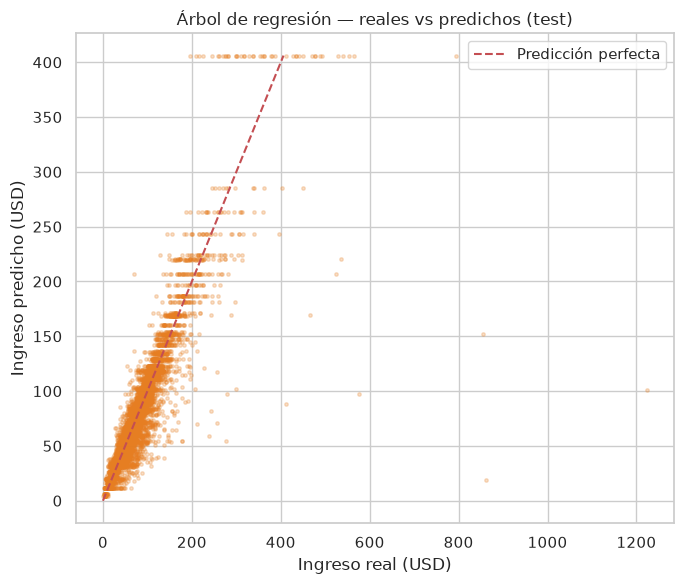

Predicción mínima: 4.66 | máxima: 406.09
Mínimo real      : 1.05 | máximo real: 1223.38


In [11]:
pred_final = arbol_final.predict(X_test)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, pred_final, s=6, alpha=0.25, color='#e67e22')
lims = [0, min(y_test.max(), pred_final.max())]
plt.plot(lims, lims, 'r--', linewidth=1.5, label='Predicción perfecta')
plt.xlabel('Ingreso real (USD)')
plt.ylabel('Ingreso predicho (USD)')
plt.title('Árbol de regresión — reales vs predichos (test)')
plt.legend()
plt.tight_layout()
plt.show()

print(f'Predicción mínima: {pred_final.min():.2f} | máxima: {pred_final.max():.2f}')
print(f'Mínimo real      : {y_test.min():.2f} | máximo real: {y_test.max():.2f}')

**Lectura:** los puntos se agrupan en **escalones horizontales**. Eso es la firma de un árbol: todos los clientes de una misma hoja reciben exactamente el mismo valor predicho. El techo de predicción está muy por debajo del ingreso máximo real: **un árbol no extrapola**, porque nunca puede predecir un valor mayor al promedio de la hoja más alta que vio en entrenamiento.


### 4.5 La curva de profundidad: el compromiso sesgo-varianza

Una de las gráficas más importantes del curso. Recorremos `max_depth` y medimos el error en train y en test.


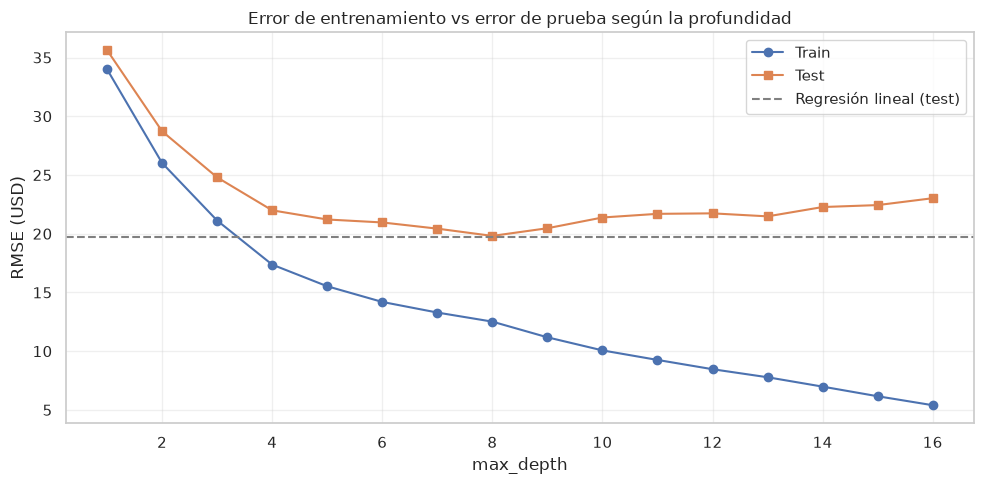

,max_depth,RMSE_train,RMSE_test
0,1,34.00,35.63
1,2,26.02,28.72
2,3,21.12,24.80
3,4,17.37,21.99
4,5,15.53,21.21
5,6,14.19,20.96
6,7,13.29,20.43
7,8,12.52,19.81
8,9,11.18,20.47
9,10,10.07,21.38


In [12]:
profundidades = range(1, 17)
filas = []

for d in profundidades:
    m = DecisionTreeRegressor(max_depth=d, random_state=SEMILLA)
    m.fit(X_train, y_train)
    filas.append({
        'max_depth': d,
        'RMSE_train': np.sqrt(mean_squared_error(y_train, m.predict(X_train))),
        'RMSE_test': np.sqrt(mean_squared_error(y_test, m.predict(X_test)))
    })

curva = pd.DataFrame(filas)

plt.figure(figsize=(10, 5))
plt.plot(curva.max_depth, curva.RMSE_train, marker='o', label='Train')
plt.plot(curva.max_depth, curva.RMSE_test, marker='s', label='Test')
plt.axhline(rmse_ols, color='gray', linestyle='--', label='Regresión lineal (test)')
plt.xlabel('max_depth')
plt.ylabel('RMSE (USD)')
plt.title('Error de entrenamiento vs error de prueba según la profundidad')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

curva.round(2)

**Lectura:** el error de **train baja siempre** con la profundidad (el árbol siempre puede ajustar más). El de **test baja hasta un punto y después sube**. Ese punto es la profundidad óptima: más allá, el árbol empieza a memorizar. Es la definición visual del sobreajuste.

**En este caso el mínimo del árbol es 19,81 USD (profundidad 8) contra 19,70 USD de la regresión lineal: quedó a 11 centavos, pero no lo superó.** La conclusión honesta es que, para este problema, el árbol no aporta precisión. No todo modelo más complejo es mejor.


### 4.6 Importancia de las variables

`feature_importances_` mide cuánto reduce el error cada variable al usarse en los cortes, ponderado por cuántos clientes pasan por esos cortes.


In [13]:
importancias = pd.DataFrame({
    'Variable': X_train.columns,
    'Importancia': arbol_final.feature_importances_
}).sort_values('Importancia', ascending=False)

importancias['%'] = (importancias['Importancia'] / importancias['Importancia'].sum() * 100).round(1)
importancias.head(15)

,Variable,Importancia,%
3,OverageMinutes,0.704538,70.5
2,TotalRecurringCharge,0.289299,28.9
1,MonthlyMinutes,0.002910,0.3
0,MonthsInService,0.001134,0.1
9,CurrentEquipmentDays,0.001100,0.1
11,PercChangeMinutes,0.000405,0.0
4,DroppedCalls,0.000266,0.0
10,AgeHH1,0.000110,0.0
8,ActiveSubs,0.000106,0.0
20,PrizmCode_Suburban,0.000049,0.0


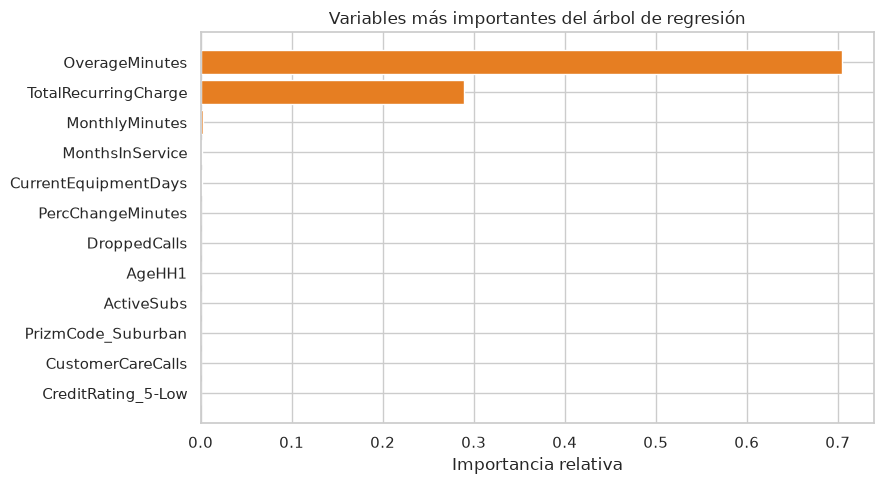

In [14]:
top = importancias.head(12).sort_values('Importancia')

plt.figure(figsize=(9, 5))
plt.barh(top.Variable, top.Importancia, color='#e67e22')
plt.xlabel('Importancia relativa')
plt.title('Variables más importantes del árbol de regresión')
plt.tight_layout()
plt.show()

**Lectura:** las variables de facturación (`TotalRecurringCharge`, `OverageMinutes`) dominan, igual que en la regresión lineal. Tiene coherencia: son las que determinan el ingreso. Que dos modelos distintos coincidan en el ranking es una **validación cruzada de la interpretación**.

Ojo con la diferencia conceptual:

- En la **regresión** la importancia se lee por el **beta estandarizado** y tiene signo (dirección).
- En el **árbol** la importancia **no tiene dirección**: dice "esta variable se usa mucho para partir", no si sube o baja el ingreso.


### 4.7 Ver las reglas del árbol

Un árbol se puede leer como una serie de reglas `si... entonces`. Esto es lo que lo hace tan útil para explicar decisiones a alguien de negocio.


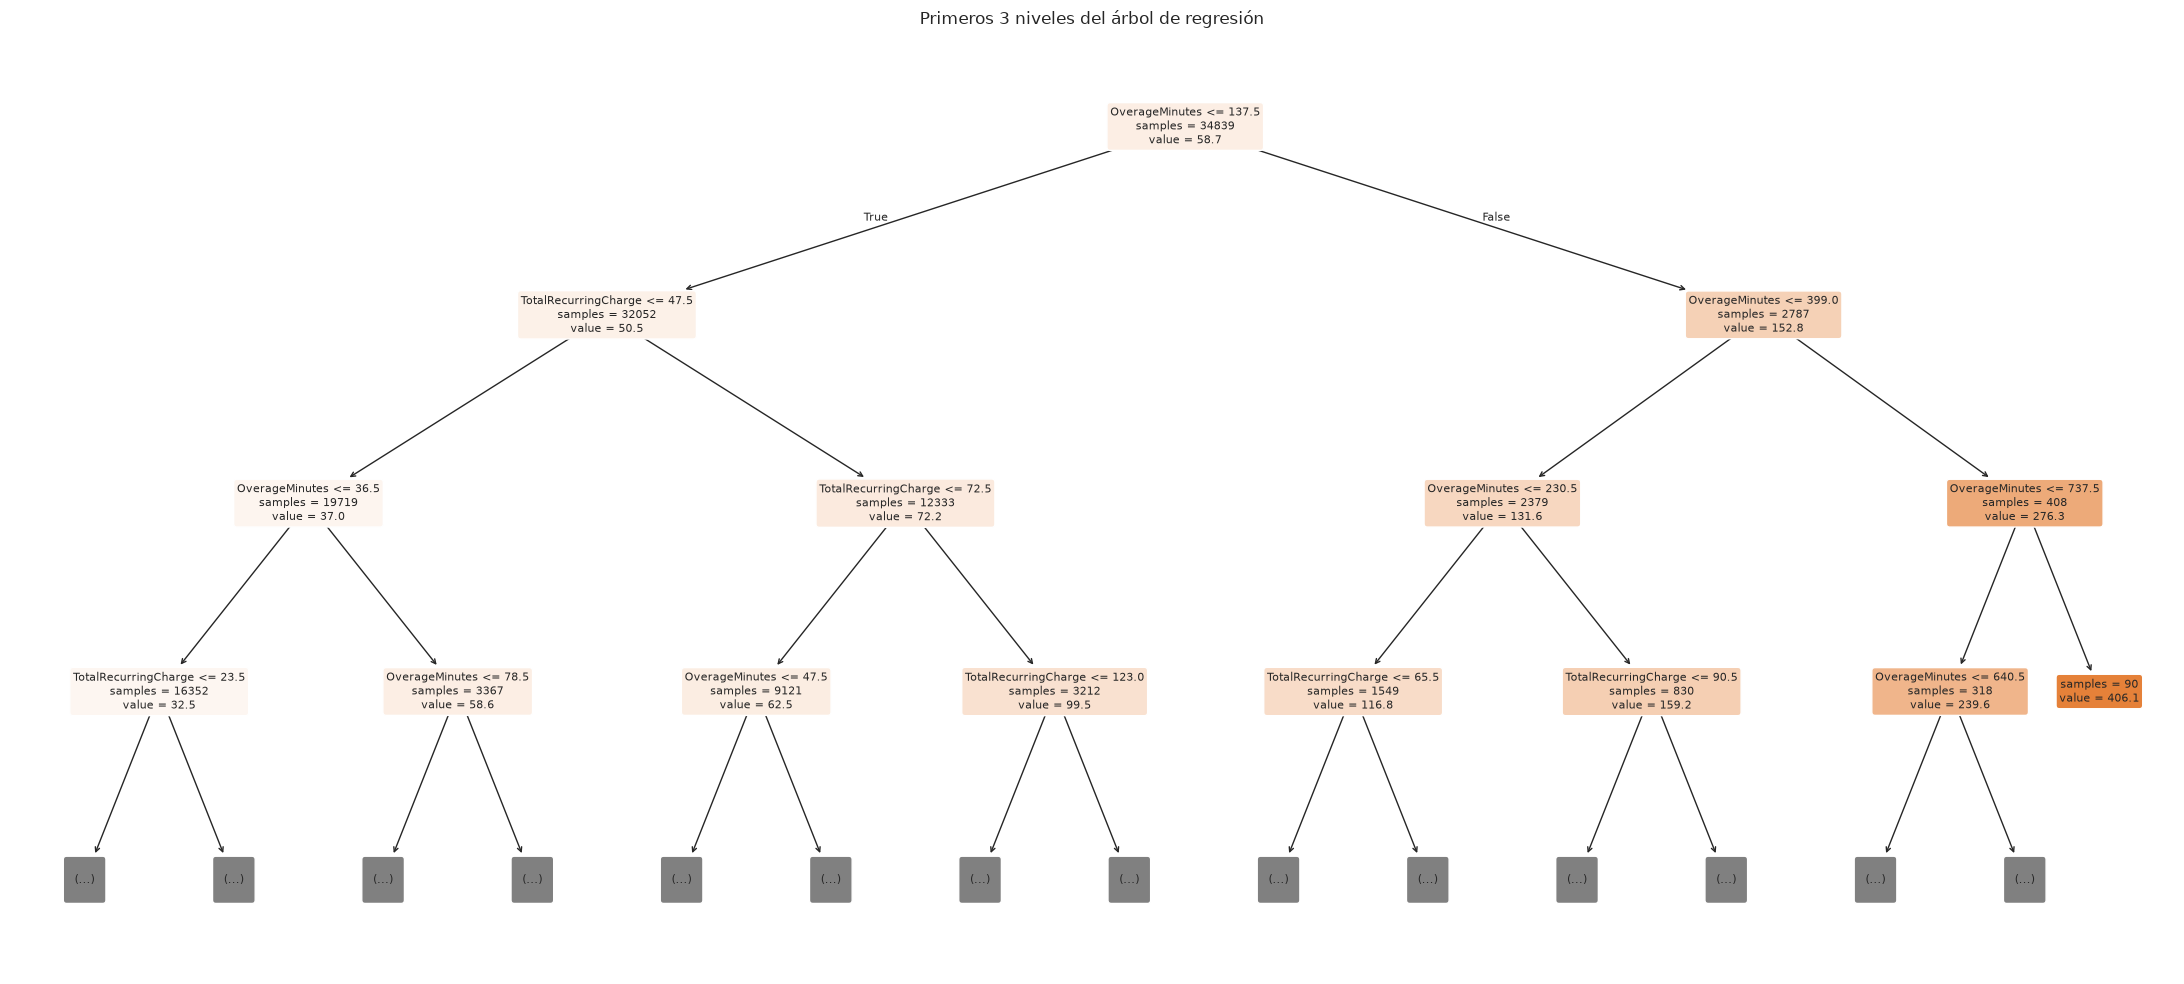

In [15]:
plt.figure(figsize=(22, 10))
plot_tree(
    arbol_final,
    max_depth=3,
    feature_names=list(X_train.columns),
    filled=True,
    rounded=True,
    impurity=False,
    precision=1,
    fontsize=8
)
plt.title('Primeros 3 niveles del árbol de regresión')
plt.tight_layout()
plt.show()

In [16]:
reglas = export_text(arbol_final, feature_names=list(X_train.columns), max_depth=3, decimals=1)
print(reglas[:3000])

|--- OverageMinutes <= 137.5
|   |--- TotalRecurringCharge <= 47.5
|   |   |--- OverageMinutes <= 36.5
|   |   |   |--- TotalRecurringCharge <= 23.5
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- TotalRecurringCharge >  23.5
|   |   |   |   |--- truncated branch of depth 7
|   |   |--- OverageMinutes >  36.5
|   |   |   |--- OverageMinutes <= 78.5
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- OverageMinutes >  78.5
|   |   |   |   |--- truncated branch of depth 7
|   |--- TotalRecurringCharge >  47.5
|   |   |--- TotalRecurringCharge <= 72.5
|   |   |   |--- OverageMinutes <= 47.5
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- OverageMinutes >  47.5
|   |   |   |   |--- truncated branch of depth 7
|   |   |--- TotalRecurringCharge >  72.5
|   |   |   |--- TotalRecurringCharge <= 123.0
|   |   |   |   |--- truncated branch of depth 7
|   |   |   |--- TotalRecurringCharge >  123.0
|   |   |   |   |--- truncated branch of depth 3
|

In [17]:
# ¿Qué predice el árbol para un cliente concreto?
cliente = X_test.iloc[[0]]
prediccion = arbol_final.predict(cliente)[0]

print('Perfil del cliente:')
print(cliente.T.to_string())
print(f'\nIngreso real      : {y_test.iloc[0]:,.2f} USD')
print(f'Ingreso predicho  : {prediccion:,.2f} USD')
print(f'Error             : {abs(y_test.iloc[0] - prediccion):,.2f} USD')

Perfil del cliente:
                              7606
MonthsInService               29.0
MonthlyMinutes                22.0
TotalRecurringCharge          32.0
OverageMinutes                 0.0
DroppedCalls                   1.0
CustomerCareCalls              0.0
RetentionCalls                 0.0
Handsets                       1.0
ActiveSubs                     2.0
CurrentEquipmentDays         857.0
AgeHH1                         0.0
PercChangeMinutes             37.0
ChildrenInHH                   0.0
CreditRating_2-High            0.0
CreditRating_3-Good            0.0
CreditRating_4-Medium          0.0
CreditRating_5-Low             0.0
CreditRating_6-VeryLow         0.0
CreditRating_7-Lowest          0.0
PrizmCode_Rural                0.0
PrizmCode_Suburban             0.0
PrizmCode_Town                 0.0
Occupation_Crafts              0.0
Occupation_Homemaker           0.0
Occupation_Other               1.0
Occupation_Professional        0.0
Occupation_Retired             0.0


## 5. SALIDA

In [18]:
print('=' * 66)
print('RESUMEN — ÁRBOL DE REGRESIÓN Cell2Cell')
print('=' * 66)
print(f'Target                : {TARGET}')
print(f'Observaciones         : {len(X):,}')
print(f'Predictores           : {X.shape[1]}')
print(f'Mejor max_depth       : {grid.best_params_["max_depth"]}')
print(f'Mejor min_samples_leaf: {grid.best_params_["min_samples_leaf"]}')
print(f'RMSE test (árbol)     : {np.sqrt(mean_squared_error(y_test, pred_final)):,.2f} USD')
print(f'RMSE test (lineal)    : {rmse_ols:,.2f} USD')
print(f'R² test (árbol)       : {r2_score(y_test, pred_final):.4f}')
print(f'R² test (lineal)      : {r2_ols:.4f}')
print(f'Variable top          : {importancias.iloc[0]["Variable"]} ({importancias.iloc[0]["%"]}%)')
print('=' * 66)

RESUMEN — ÁRBOL DE REGRESIÓN Cell2Cell
Target                : MonthlyRevenue
Observaciones         : 49,770
Predictores           : 32
Mejor max_depth       : 10
Mejor min_samples_leaf: 50
RMSE test (árbol)     : 20.25 USD
RMSE test (lineal)    : 19.70 USD
R² test (árbol)       : 0.8002
R² test (lineal)      : 0.8109
Variable top          : OverageMinutes (70.5%)


### Conclusiones

1. **El sobreajuste es real y se ve:** un árbol sin límite acierta casi perfecto en train y cae en test. La poda por hiperparámetros no es opcional.
2. **La curva de profundidad muestra el punto óptimo** y es la herramienta para encontrarlo sin adivinar.
3. **El árbol no superó a la regresión lineal** en este problema. Y eso es un resultado, no un fracaso: cuando el fenómeno es aditivo (el ingreso es una suma de cargos), un modelo lineal simple es difícil de vencer.
4. **Coincidencia en el ranking de variables** con la regresión (`TotalRecurringCharge`, `OverageMinutes`), lo que refuerza la lectura de negocio: el ingreso lo mueve la facturación, no la demografía.
5. **El árbol gana en explicabilidad operativa:** se puede convertir en reglas (`si... entonces`) y explicar a un área no técnica.

**Cuándo usar cada uno:**

| Situación | Modelo recomendado |
|---|---|
| Relación aditiva, se busca precisión | Regresión lineal |
| Relación con umbrales y no linealidades | Árbol |
| Se necesita explicar la decisión paso a paso | Árbol |
| Se necesita el efecto (signo y magnitud) de cada variable | Regresión |

**Siguiente paso:** el proyecto sigue con `KMeans_Segmentacion_Cell2Cell.ipynb`, donde se abandona la etiqueta y se buscan grupos naturales de clientes.
